## to do:

QoL
- plot nodes at any level of transform, see all_nodes
- automatically perform max. level transform
- plot single node by path
- time [s] instead of coefficient number
- automatically perform nodes2data on inverse
- fix plots

visualisation:
- graph neural network (python package)
- add scientific form to heisenberg plot
- add automatic ticks formatting to heisenberg plot?

studentship:
- sensitivity analysis
- testing/tuning thresholding values (classification without machine learning)
- validate kurtosis and crest factor
- test border effects on kurtosis and crest factor
- test with data length of power of 2
- develop classifier
- clustering (e.g. k-means) using energy, kurtosis, crest factor is input features.
- 8 pages for manuscript
- normalise clustering
- look at effect of number of clusters
- learn about k-means and how it's used (reaserch)
- look at how it's used with dwpt
- explain and justify procedure for classification using research
- ksvd, knn
- settle on a method by next meeting
- number of clusters
- break down notebook
- measuring effectiveness of k-means
- rename notebooks
- read about theory
- implement neural networks
- learn about k-means
- write manuscript: add literature review
- random forest
- and other machine learning algorithms that sound fun
- look at to fix in k-means file
- write statistical_feature_calculation.py file
- implement simple neural network (do reserach, learn about other peoples' solutions)
- neural networks k-means
- reserach other machine learning methods

- check sum of reconstructed nodes is the same as reconstructing them both at once.
- use k-means + soft k-means for classification.
- use pandas dataframe for notebooks
- use pd dataframe for wavelet transform object as well

- check out tree diagram
- add functionality to base node
- mess around with statistical measures used in training data
- change number of clusters.
- hyperparameter tuning
- ensure reproducibility
- upload references

- study consistency of statistical measures: signal length, level of transform, wavelet, padding.
- use dynamics data

- sounds like a report. manuscript should be concise.
- explain the problem you're trying to address in the intro. as well as physics (materials and methods.)
- trying to find a quantitative relationship between cavitation and physical effects.
- literature survey on acoustic emission processing using wavevlet packets specifically for acoustic cavitation.
- try conda for pygraphviz, install all libraries again
- upload papers to reference folder.
- check things are working before pushing. check everything again
- work on k-means with the c-means updates
- test k-means with new implementation of entropy, and 4 metrics
- write up results for bubble dynamics and k-means
- finish c-means: get parameters and stuff
- upload latex text document onto new branch

Reza
- bubble dynamics

# Decompose a signal to its components at different frequency bands with WPT

In this notebook we aim to test WPT for extracting different components of a signal based on the energy, kurtosis, and crest factor of different frequency bands. The WPT library requires python3.6+ version. The following cell checks this requirement.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

Import the wavelet_transform package and required libraries.

In [2]:
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats

# matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np
import pywt
import scipy.stats as sc

Specify the parameters for generating a synthetic signal and to perform wavelet packet transform.

In [21]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [1, 0.8, 0.4]  # amplitude of each sine wave
frequencies = [5, 15, 25]  # frequency content of signal
phases = [0, np.deg2rad(45), np.deg2rad(120)]  # phase of each sine wave

duration = 1000 / min(frequencies)  # duration of wave

trans_amp = [10 for _ in range(5)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db20"
levels = 5
mode = "symmetric"

sort_by = 'energy'  # 'energy', 'kurtosis', 'crest', 'False' -> freq
sort = "rec"  # 'rec' (reconstructed signal) 'coef' (transform coefficients)
n_highest = 3

fft_lim = 50  # increase value to view more of the fft plots

Generate synthetic multitonal signal with/without additive noise. We will fft the signal to double check the frequency contents.

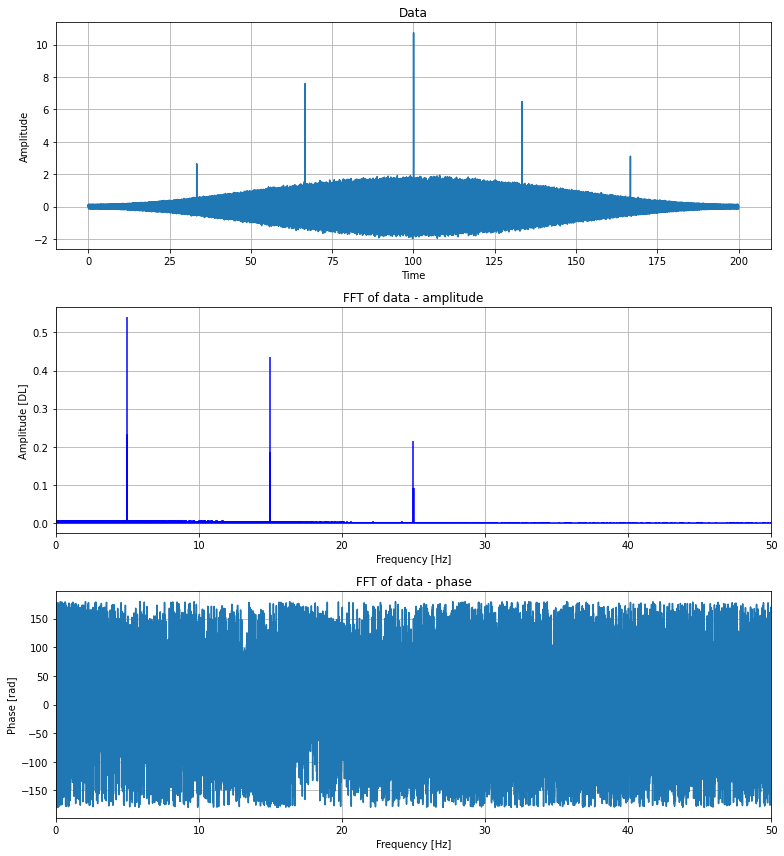

In [22]:
# generate sound wave
data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
data += sd.transients(trans_amp, trans_time, trans_dur, duration, sampling_rate)
data += sd.noise(std_noise,duration,sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

### Frequency content of reconstructed subbands
Decompose signal using discrete wavelet packet transform and sort the nodes in order of energy, kurtosis, or crest factor.

functions used for sorting

In [23]:
def sort_nodes(rec, sort="rec", sort_by="energy"):
    """
    choose how to sort the subbands

    Parameters
    ----------
    rec: tuple
        tuple containing (coefficients,reconstructed_wave,fft_of_rec_wave,energy,kurtosis,crest)
    sort: str
        sort by 'energy', 'kurtosis', or 'crest' factor
    coef_or_rec: str
        sort by calculating attributes of the node coefficients or the reconstructed wave

    returns
    -------
    rec: tuple
        sorted input
    """
    if sort == "rec":
        if sort_by == "energy": 
            return sorted(rec, key=lambda x: x[3], reverse=True)
        elif sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[4], reverse=True)
        elif sort_by == "crest":
            return sorted(rec, key=lambda x: x[4], reverse=True)
            


    elif sort == "coef":
        if sort_by == "energy":
            return sorted(rec, key=lambda x: x[0].energy, reverse=True)
        if sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[0].kurtosis, reverse=True)
        if sort_by == "crest":
            return sorted(rec, key=lambda x: x[0].crest_factor, reverse=True)

Transform and sort nodes

In [24]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
rec = []

for node in tr_ob.get_level(order="freq"):
    inverse = inv.inv_dwpt(tr_ob, nodes=node)
    inverse_signal_length = len(inverse)
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )
    energy = stats.energy(inverse)
    kurtosis = sc.kurtosis(inverse)
    crest = stats.crest_factor(inverse)
    entropy = stats.entropy(inverse)
    rec.append((node, inverse, fft, energy, kurtosis, crest, entropy))

plot the **`n_highest`** energy components (subbands).

In [25]:
def plot_reconstructions(rec, n_highest=None, group=None):
    partial_rec = np.zeros(signal_length)  # track sum of highest energy subbands
    if n_highest is None:
        n_highest = len(rec)
    for i, rec in enumerate(rec[:n_highest]):  # highest energy, kurtosis, etc.
        node, rec_wave, fft, energy, kurtosis, crest, entropy = rec
        partial_rec += rec_wave  # full reconstruction
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = node.frequency_range
        ax[0].plot(t_plot, rec_wave)
        title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(fft),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed subband")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()

        # print info
        print(f"energy of recovered signal: {energy}")
        print(f"kurtosis of recovered signal: {kurtosis}")
        print(f"crest factor of recovered signal: {crest}")
        print(f"entropy of recovered signal: {entropy}")
        print()
        print(f"energy of node coefficients: {node.energy}")
        print(f"kurtosis of node coefficients: {node.kurtosis}")
        print(f"crest factor of node coefficients: {node.crest_factor}")
        print(f"entropy of node coefficinets: {node.entropy}")
    return partial_rec

run = False
if run is True:
    # sort reconstructed waves
    sorted_rec = sort_nodes(rec, sort, sort_by)
    print(f"sorted by: {sort_by} of {sort}")
    # plot highest energy subbands
    partial_rec = plot_reconstructions(sorted_rec,n_highest)

### heisenberg visualisation

Making an heisenberg plot of the last level of dwpt

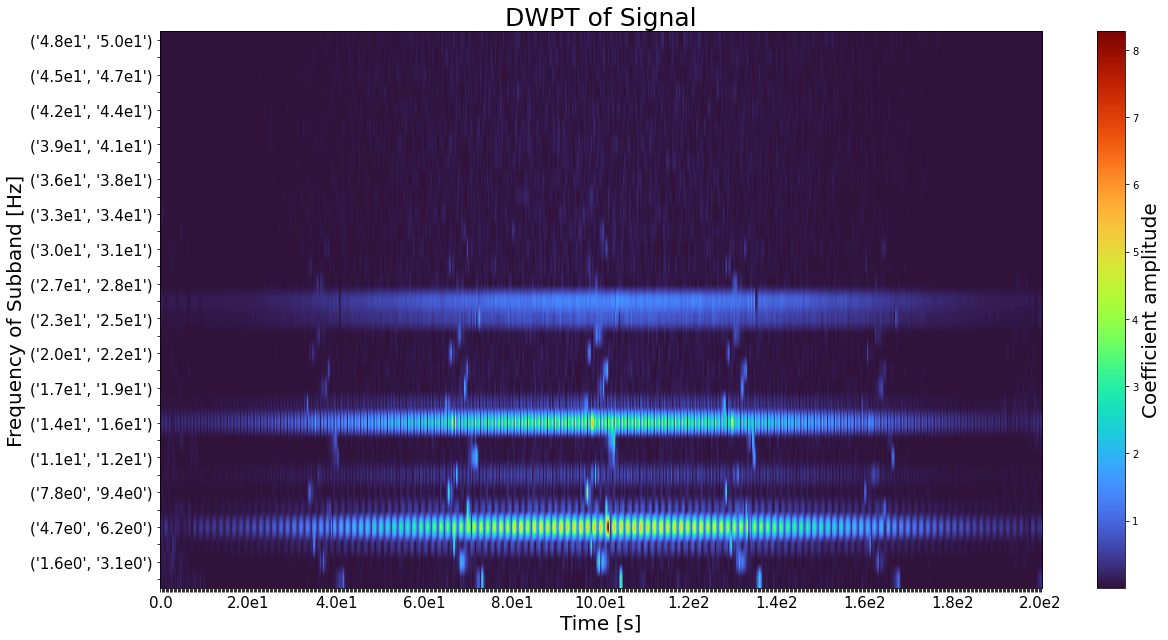

In [26]:
plot.heisenberg(tr_ob, max(t_plot))

### Clustering

k-means clustering algorithm with energy, kurtosis, and crest factor as the input

In [27]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
data_train = []
for node, inverse, _, energy, kurtosis, crest, entropy in rec:
    data_train.append(
        (energy, kurtosis, crest, entropy)
        )

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 5
kmeans = KMeans(n_clusters=no_clusters)
kmeans.fit(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

### plot result

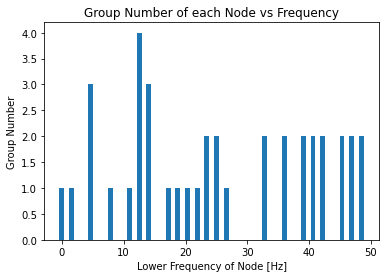

Cluster labels: [1 1 0 3 0 1 0 1 4 3 0 1 1 1 1 2 2 1 0 0 0 2 0 2 0 2 2 2 0 2 2 2]
highest energy: 3
highest kurtosis: 4
highest crest factor: 4


In [28]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node,*_ in rec], labels)
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

print("Cluster labels:", labels)
print(f"highest energy: {np.argmax(centers[:,0])}")
print(f'highest kurtosis: {np.argmax(centers[:,1])}')
print(f'highest crest factor: {np.argmax(centers[:,2])}')

### PCA

In [29]:
# apply PCA to training data
pca = PCA(n_components=3)
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters)
kmeans_pca.fit(data_pca)

labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(pca.inverse_transform(kmeans_pca.cluster_centers_))

### Plot PCA Result

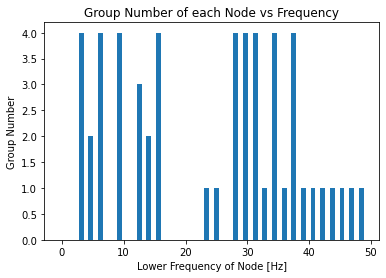

Eigenvectors:
Energy, Kurtosis, Crest factor, Peak, Mean
[[-0.24  0.55  0.56 -0.57]
 [ 0.96  0.24  0.02 -0.14]
 [-0.15  0.61 -0.77 -0.11]]
Eigenvalues: [2.97 0.94 0.17]
Cluster labels: [0 0 4 2 4 0 4 0 3 2 4 0 0 0 0 1 1 0 4 4 4 1 4 1 4 1 1 1 1 1 1 1]
highest PC1: 2
highest PC2: 3
highest PC3: 3


In [30]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node,*_ in rec]
plt.bar([node.frequency_range[0] for node,*_ in rec], labels_pca)
plt.tick_params
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print('Energy, Kurtosis, Crest factor, Peak, Mean')
print(np.round(eigenvectors,2))

print("Eigenvalues:", np.round(eigenvalues,2))

print("Cluster labels:", labels_pca)
print(f"highest PC1: {np.argmax(centers_pca[:,0])}")
print(f'highest PC2: {np.argmax(centers_pca[:,1])}')
print(f'highest PC3: {np.argmax(centers_pca[:,2])}')

### 3d plot

3d plots of the results with axes energy, kurtosis, crest factor

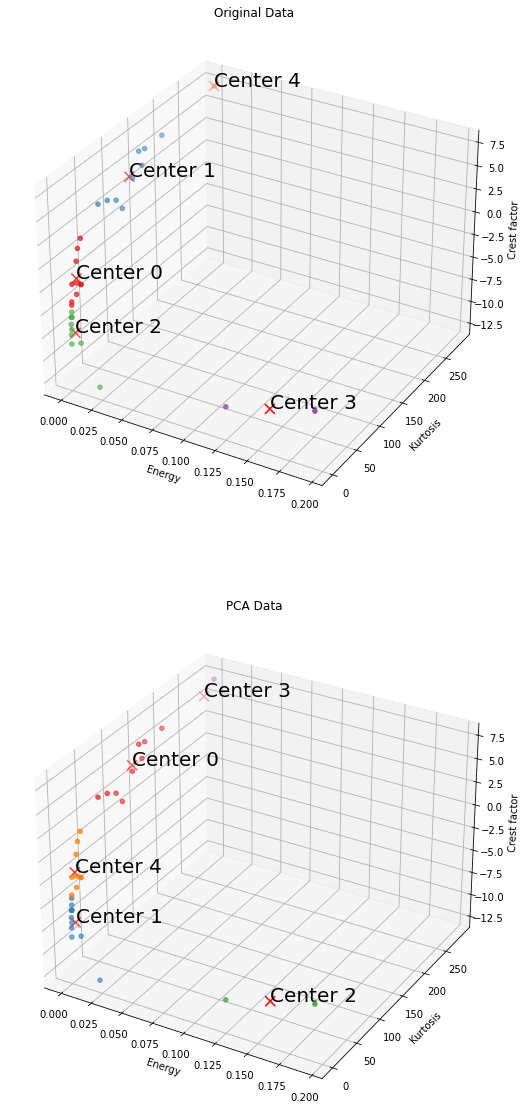

In [31]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={'projection': '3d'})

titles = ['Original Data', 'PCA Data']

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap('Set1')
    if i == 0:
        data_scatter = data_train
        centers_scatter = centers
        labels_scatter = labels
    else:
        data_scatter = data_train
        centers_scatter = centers_pca
        labels_scatter = labels_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        c=[cmap(label) for label in labels_scatter])
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c='red', marker='x', s=100)
    
    ax.set_xlabel('Energy')
    ax.set_ylabel('Kurtosis')
    ax.set_zlabel('Crest factor')
    ax.set_title(titles[i])

    # Annotate cluster centers with their positions
    for i, center in enumerate(centers_scatter):
        ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

plt.show()

### 2d plot

plots with energy vs crest factor comparing PCA and no PCA results

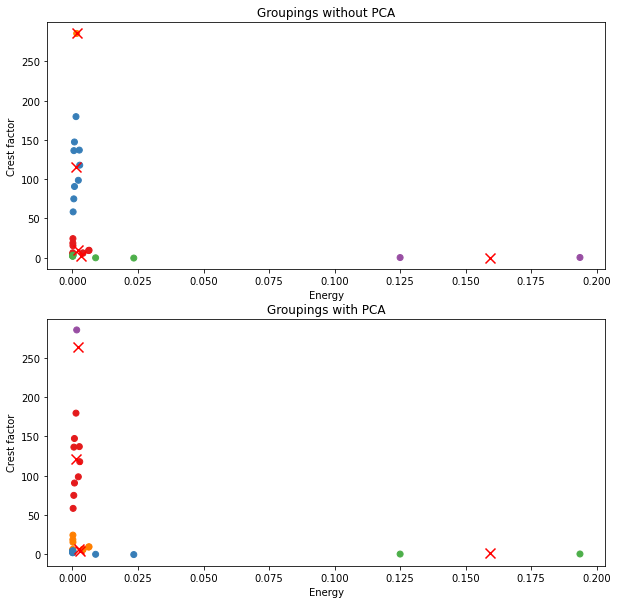

In [32]:
# 3d plot
fig, ax = plt.subplots(2,figsize=(10,10))

# plot with colours for each cluster
cmap = plt.cm.get_cmap('Set1')
x = 0  # 0 -> energy, 1 -> kurtosis, 3 -> crest
y = 1  # ""
data_scatter = data_train
labels_scatter = labels
ax[0].scatter(
    [point[x] for point in data_scatter],
    [point[y] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
labels_scatter = labels_pca
ax[1].scatter(
    [point[x] for point in data_scatter],
    [point[y] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
# plot centres
centers_scatter = centers
ax[0].scatter(centers_scatter[:, x], 
           centers_scatter[:, y], c='red', marker='x', s=100)
centers_scatter = centers_pca
ax[1].scatter(centers_scatter[:, x], 
           centers_scatter[:, y], c='red', marker='x', s=100)
for i in range(2):
    ax[i].set_xlabel('Energy')
    ax[i].set_ylabel('Crest factor')
ax[0].set_title('Groupings without PCA')
ax[1].set_title('Groupings with PCA')
plt.show()

### Results

Plotting the reconstructed waves from clustering with their assigned group

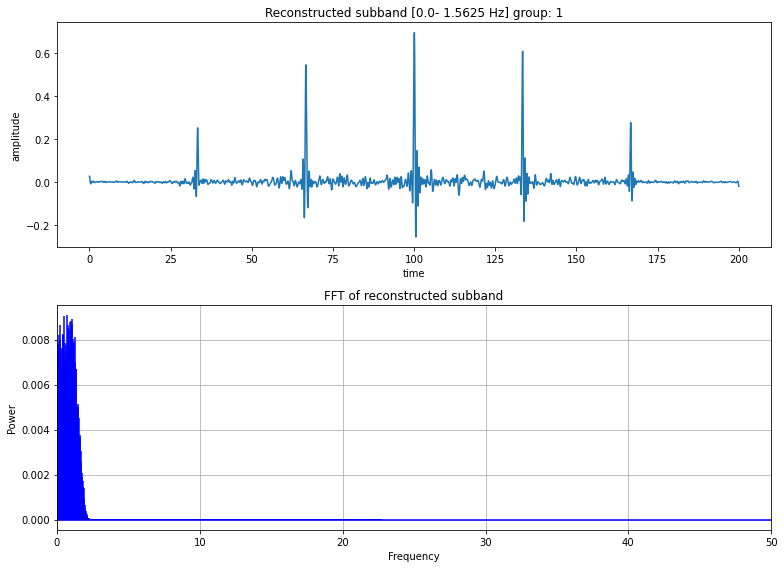

energy of recovered signal: 0.0022555317877427507
kurtosis of recovered signal: 98.49941417362042
crest factor of recovered signal: 1.7935034566800343
entropy of recovered signal: 5.913895286311434

energy of node coefficients: 0.0689010823200362
kurtosis of node coefficients: 102.66467619772813
crest factor of node coefficients: 9.016201495301631
entropy of node coefficinets: 2.624525513140546


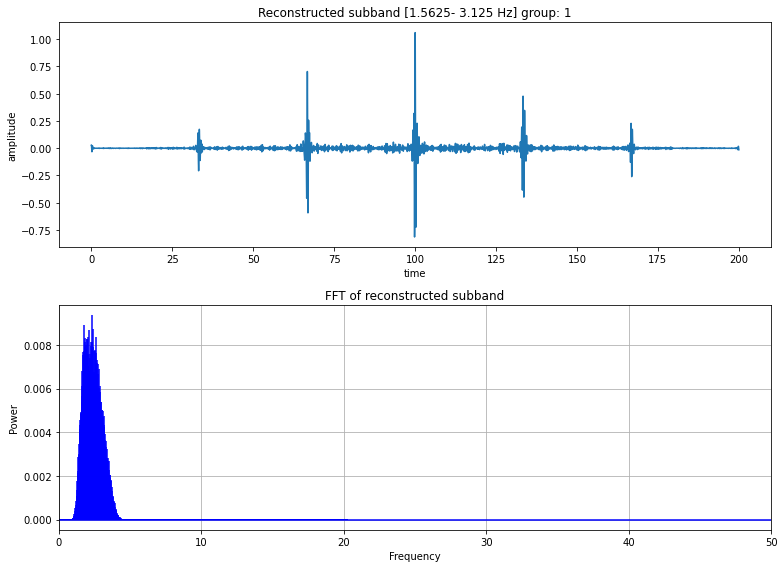

energy of recovered signal: 0.002630770281745999
kurtosis of recovered signal: 136.96756208853097
crest factor of recovered signal: 4.80522490589517
entropy of recovered signal: 5.793242741207472

energy of node coefficients: 0.07980684546736291
kurtosis of node coefficients: 48.73477883955413
crest factor of node coefficients: 6.8101328716970055
entropy of node coefficinets: 3.207215824809321


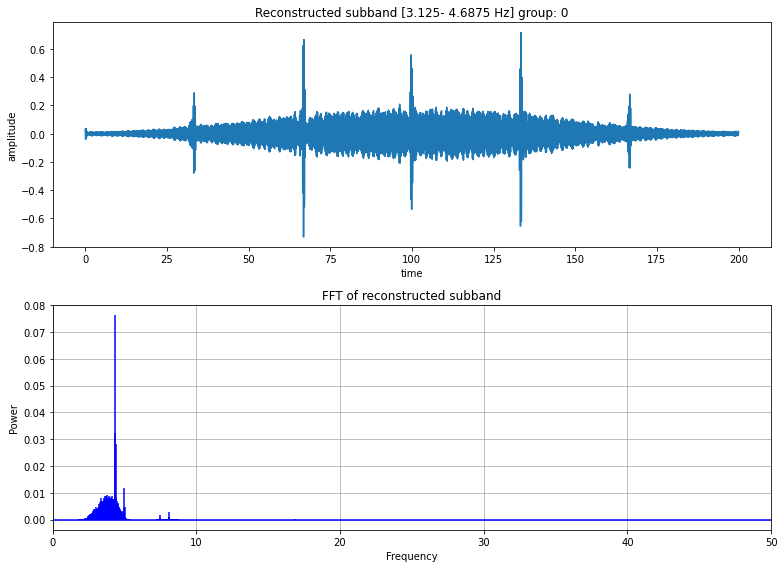

energy of recovered signal: 0.006342665052456807
kurtosis of recovered signal: 9.371725225854105
crest factor of recovered signal: -2.2521254372128086
entropy of recovered signal: 8.584870392650211

energy of node coefficients: 0.19207783180572877
kurtosis of node coefficients: 13.767532109555066
crest factor of node coefficients: 3.9888479568213473
entropy of node coefficinets: 5.094011733361829


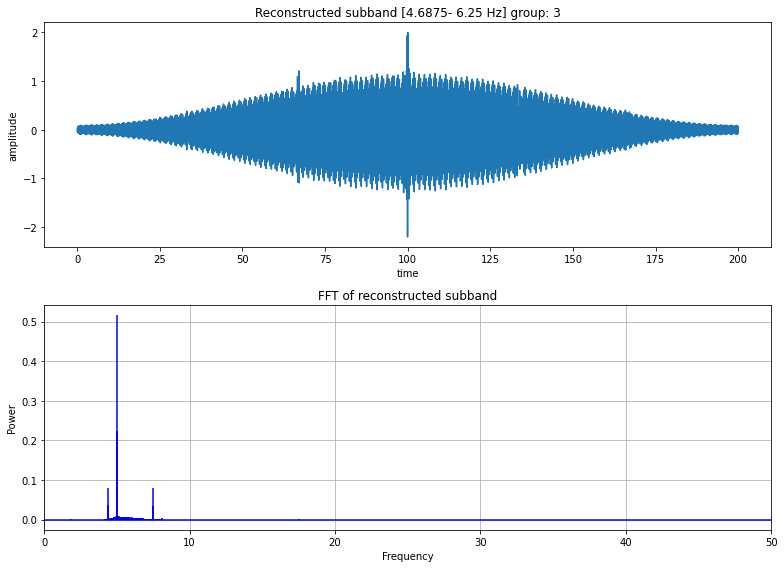

energy of recovered signal: 0.1935795839905486
kurtosis of recovered signal: 0.18057663540743096
crest factor of recovered signal: -7.500455875865586
entropy of recovered signal: 9.066215904098167

energy of node coefficients: 5.851659007917003
kurtosis of node coefficients: 3.059370068169033
crest factor of node coefficients: -3.4230587062728945
entropy of node coefficinets: 5.65579073486983


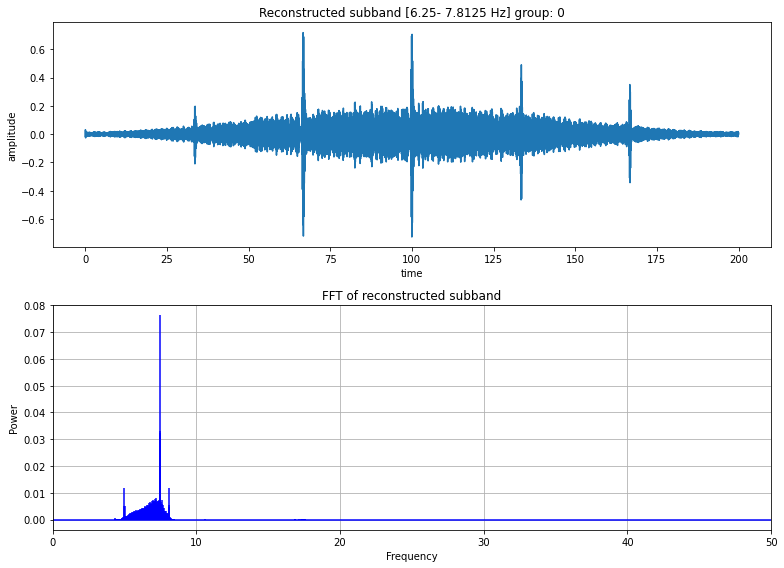

energy of recovered signal: 0.006182873807327695
kurtosis of recovered signal: 8.977040632809047
crest factor of recovered signal: -2.1875507435544037
entropy of recovered signal: 8.611151027625528

energy of node coefficients: 0.18708028829768816
kurtosis of node coefficients: 11.067146126379647
crest factor of node coefficients: 3.2422033816824207
entropy of node coefficinets: 5.2009436206563775


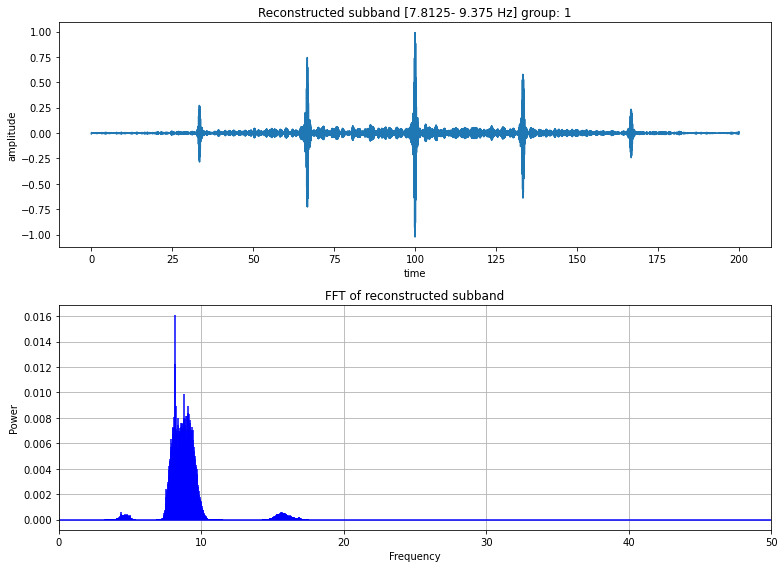

energy of recovered signal: 0.002787153585789889
kurtosis of recovered signal: 117.77531836571715
crest factor of recovered signal: 4.24321844814009
entropy of recovered signal: 6.09232629824694

energy of node coefficients: 0.08426293377518587
kurtosis of node coefficients: 128.46457585233347
crest factor of node coefficients: 9.55019874353249
entropy of node coefficinets: 2.5441133183411067


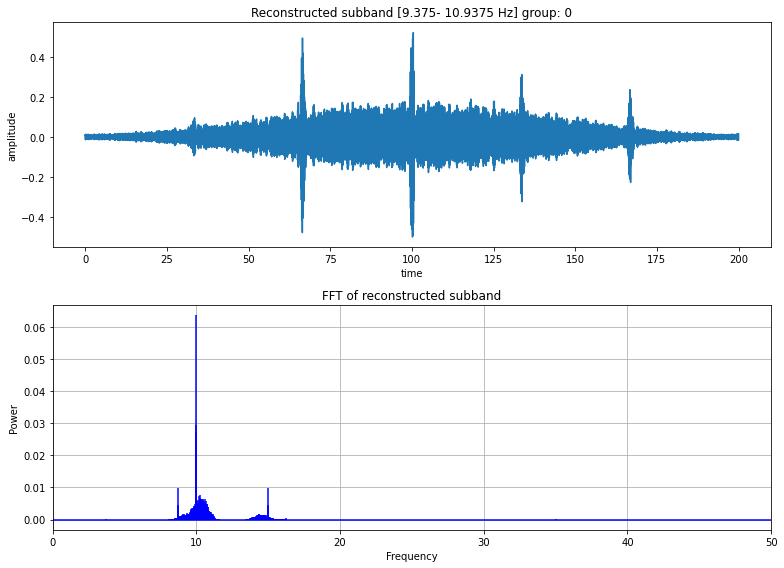

energy of recovered signal: 0.004013057287435034
kurtosis of recovered signal: 5.566617058095012
crest factor of recovered signal: -3.207881178801938
entropy of recovered signal: 8.698184682343006

energy of node coefficients: 0.12133474610410619
kurtosis of node coefficients: 10.702406006425544
crest factor of node coefficients: 3.1748202355380952
entropy of node coefficinets: 5.238564573534072


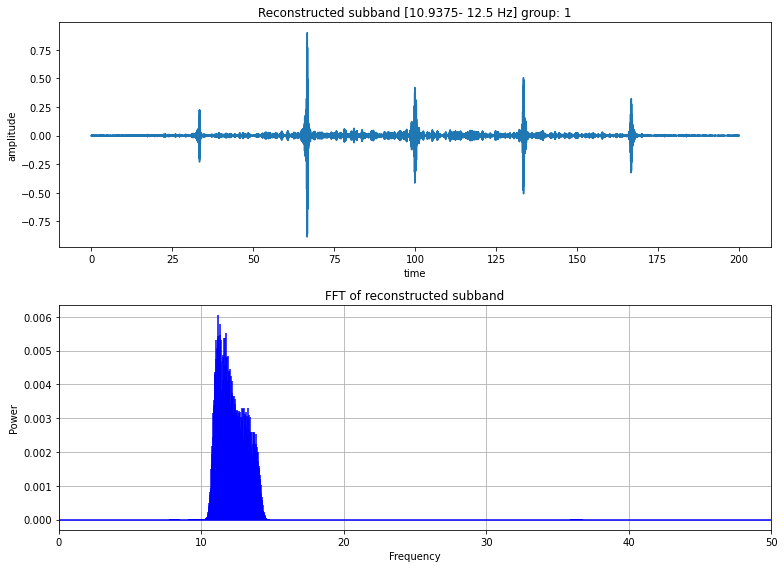

energy of recovered signal: 0.001361426407936605
kurtosis of recovered signal: 179.60800397481637
crest factor of recovered signal: 6.234091652626884
entropy of recovered signal: 5.788352054691046

energy of node coefficients: 0.041211841450613095
kurtosis of node coefficients: 64.0537441109762
crest factor of node coefficients: 7.518113008182717
entropy of node coefficinets: 3.068646790655139


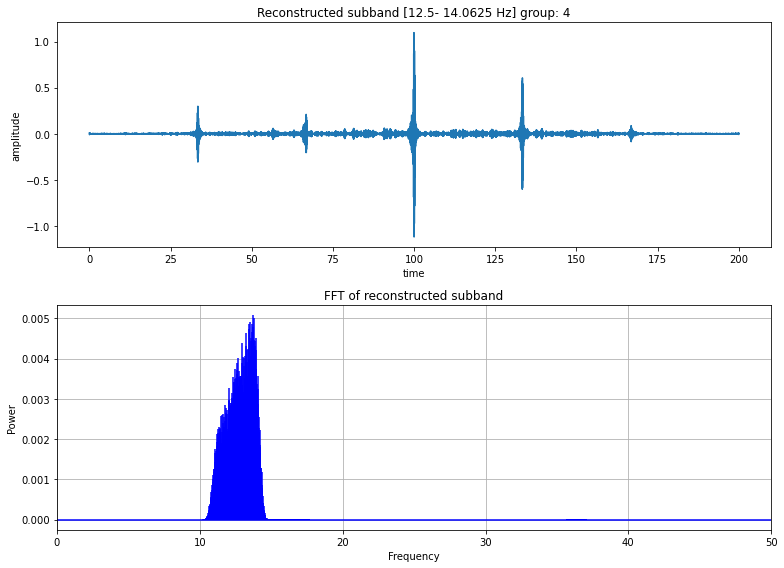

energy of recovered signal: 0.0016294777754340536
kurtosis of recovered signal: 285.59536834348387
crest factor of recovered signal: 7.3532056359952245
entropy of recovered signal: 5.264902874197355

energy of node coefficients: 0.049438054959982616
kurtosis of node coefficients: 98.27627743122495
crest factor of node coefficients: 8.908712547174169
entropy of node coefficinets: 2.6976562761964775


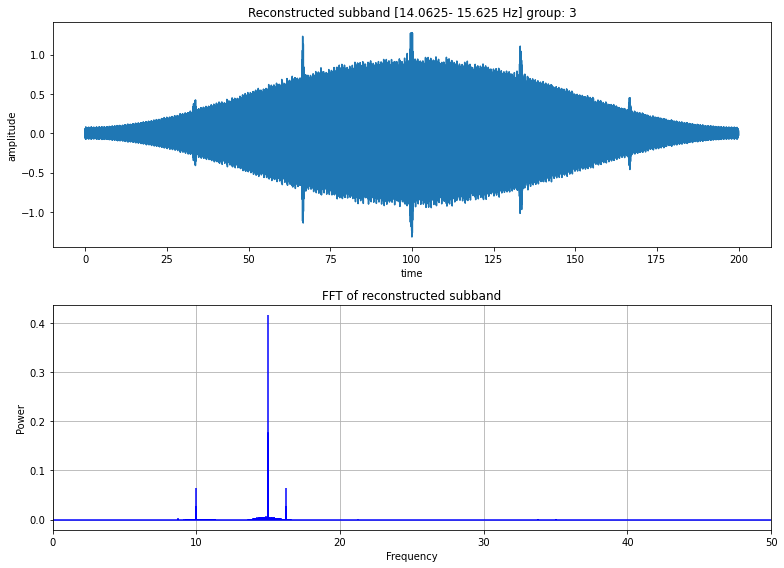

energy of recovered signal: 0.12498644692427727
kurtosis of recovered signal: 0.07235471387399972
crest factor of recovered signal: -10.068916202075025
entropy of recovered signal: 9.074865267036856

energy of node coefficients: 3.778486605214251
kurtosis of node coefficients: 2.9392497341378236
crest factor of node coefficients: -4.797235933137763
entropy of node coefficinets: 5.665667767518538


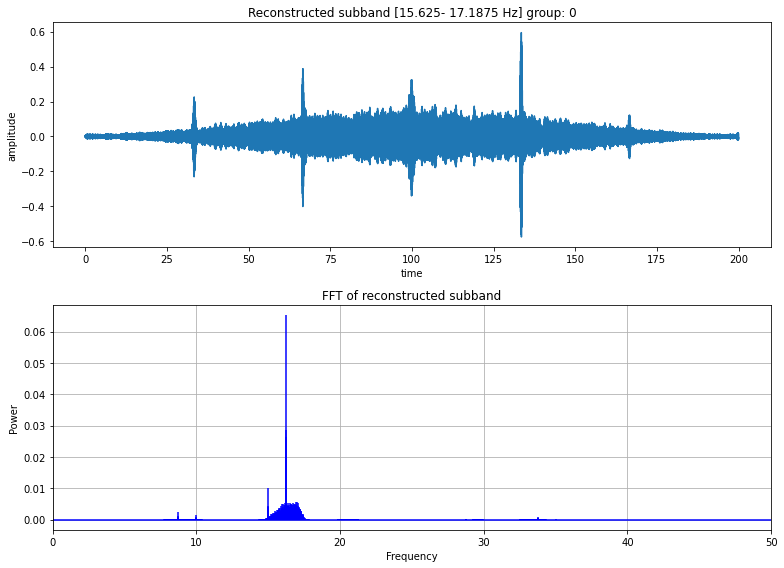

energy of recovered signal: 0.003962713466742991
kurtosis of recovered signal: 5.999839621928263
crest factor of recovered signal: -2.006622953149966
entropy of recovered signal: 8.740907640717554

energy of node coefficients: 0.1200976753124826
kurtosis of node coefficients: 7.235845814233909
crest factor of node coefficients: 2.626360095325216
entropy of node coefficinets: 5.369861923912184


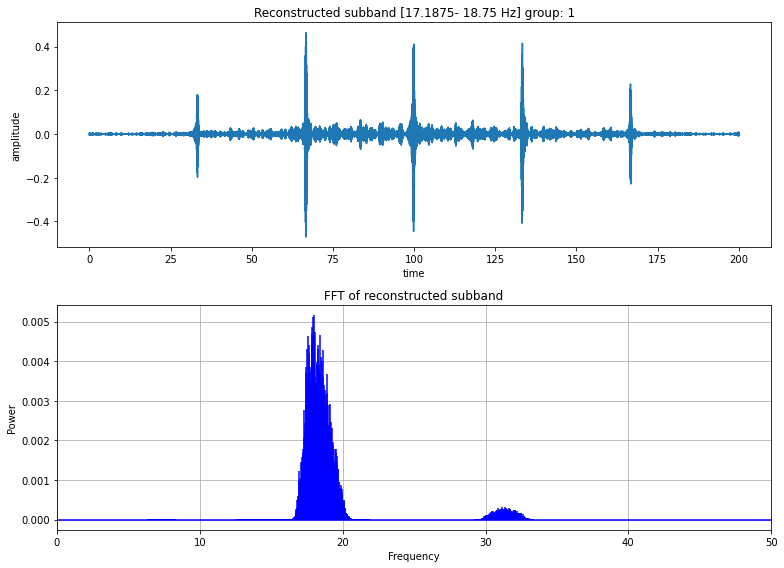

energy of recovered signal: 0.0007924054413452545
kurtosis of recovered signal: 90.56891767296725
crest factor of recovered signal: 2.9731053134932783
entropy of recovered signal: 6.356824765170292

energy of node coefficients: 0.02387800171504988
kurtosis of node coefficients: 77.52950321088923
crest factor of node coefficients: 7.928924788158863
entropy of node coefficinets: 3.1099676444238287


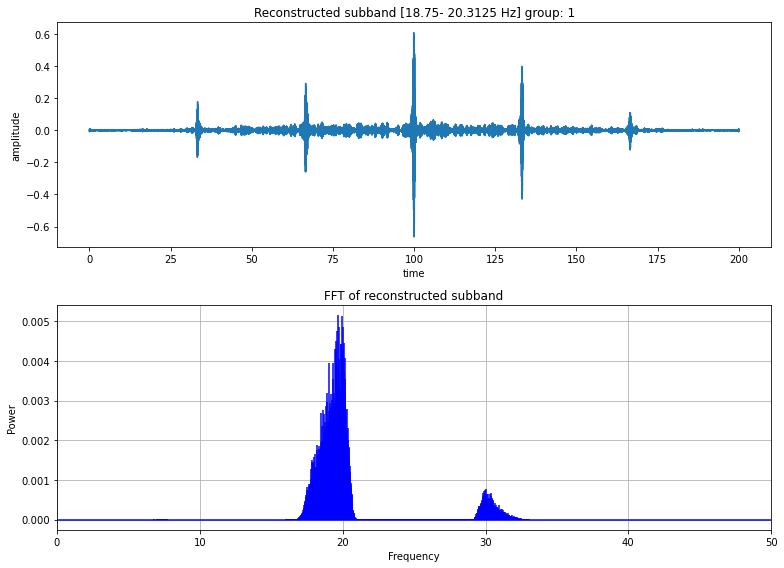

energy of recovered signal: 0.0007672266077616417
kurtosis of recovered signal: 147.3058049407869
crest factor of recovered signal: 6.101224087352937
entropy of recovered signal: 6.170126215691961

energy of node coefficients: 0.023157968312338836
kurtosis of node coefficients: 67.51307517201097
crest factor of node coefficients: 8.081235862723764
entropy of node coefficinets: 3.2296546676621842


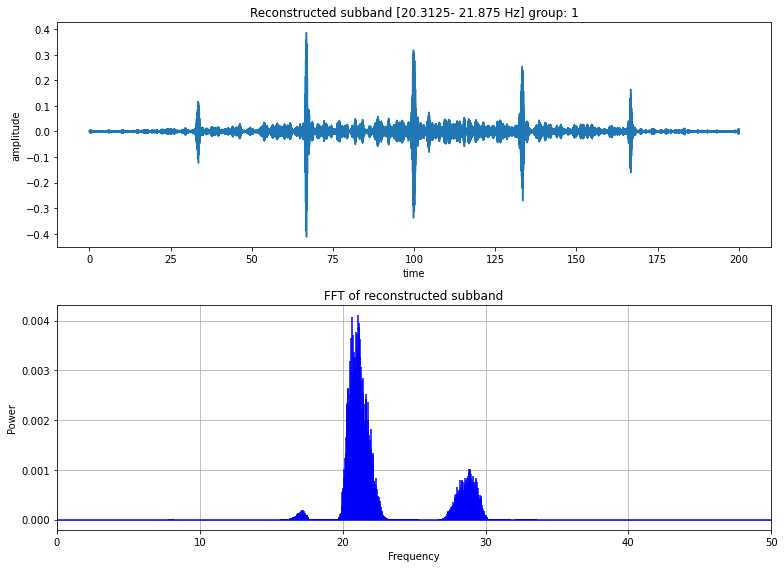

energy of recovered signal: 0.0005221099626430248
kurtosis of recovered signal: 74.84217150529933
crest factor of recovered signal: 3.629158259844054
entropy of recovered signal: 6.740303208973809

energy of node coefficients: 0.01583342072999905
kurtosis of node coefficients: 55.35343530519327
crest factor of node coefficients: 6.033383193653112
entropy of node coefficinets: 3.450123964628362


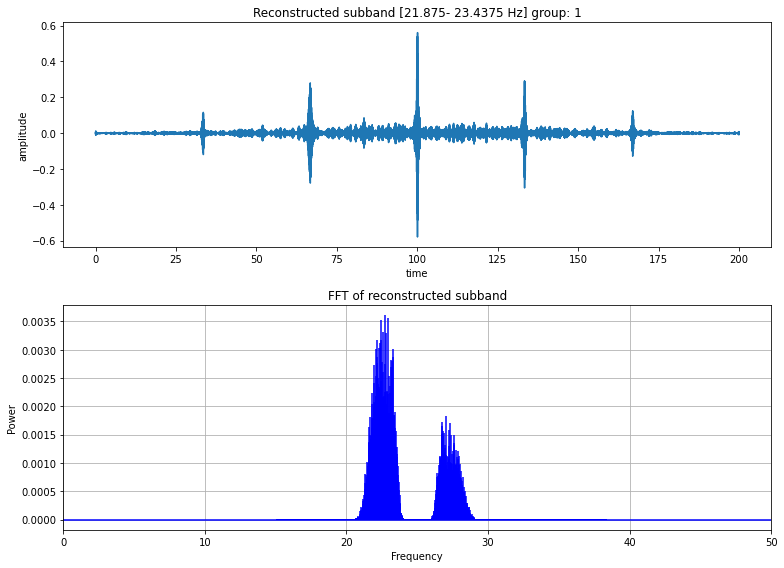

energy of recovered signal: 0.0005600155938498085
kurtosis of recovered signal: 136.29388786957043
crest factor of recovered signal: 6.276690545547959
entropy of recovered signal: 6.418620269016877

energy of node coefficients: 0.016965398541893138
kurtosis of node coefficients: 44.27272753914967
crest factor of node coefficients: 6.95824527561567
entropy of node coefficinets: 3.7321709050592364


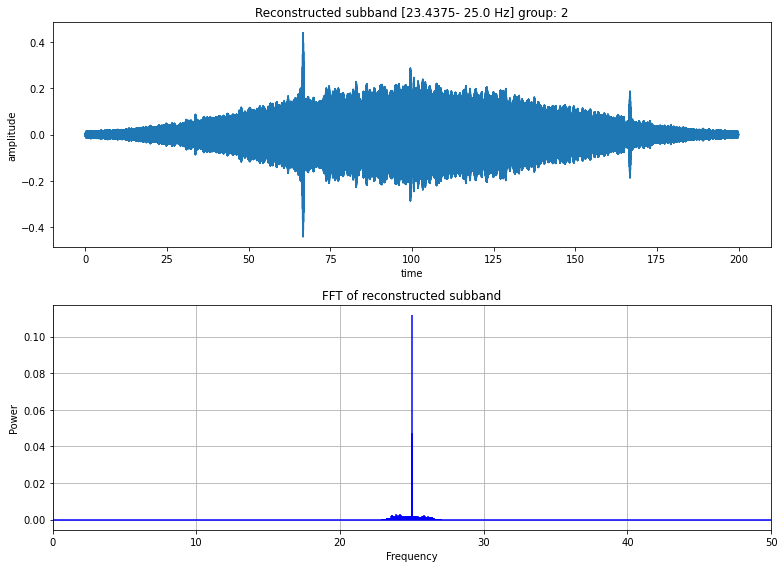

energy of recovered signal: 0.008848904287133261
kurtosis of recovered signal: -0.24125979610095438
crest factor of recovered signal: -8.073308404769579
entropy of recovered signal: 9.227035164382354

energy of node coefficients: 0.08823019825154942
kurtosis of node coefficients: 2.6911322781001057
crest factor of node coefficients: -3.4173468474085626
entropy of node coefficinets: 5.921427424700729


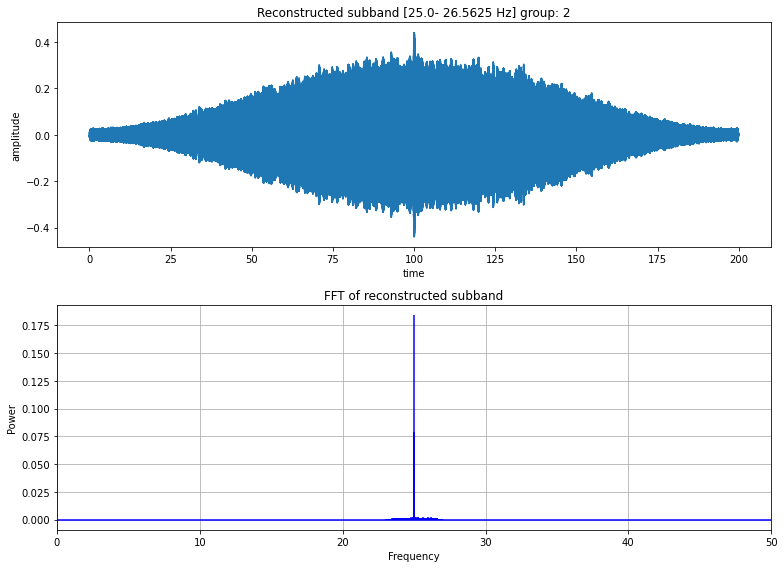

energy of recovered signal: 0.023405116775402114
kurtosis of recovered signal: -0.5761212516032668
crest factor of recovered signal: -12.320328055341898
entropy of recovered signal: 9.271260830309057

energy of node coefficients: 0.21927695490835386
kurtosis of node coefficients: 1.6333852333461063
crest factor of node coefficients: -7.898691917638535
entropy of node coefficinets: 5.9590828105999725


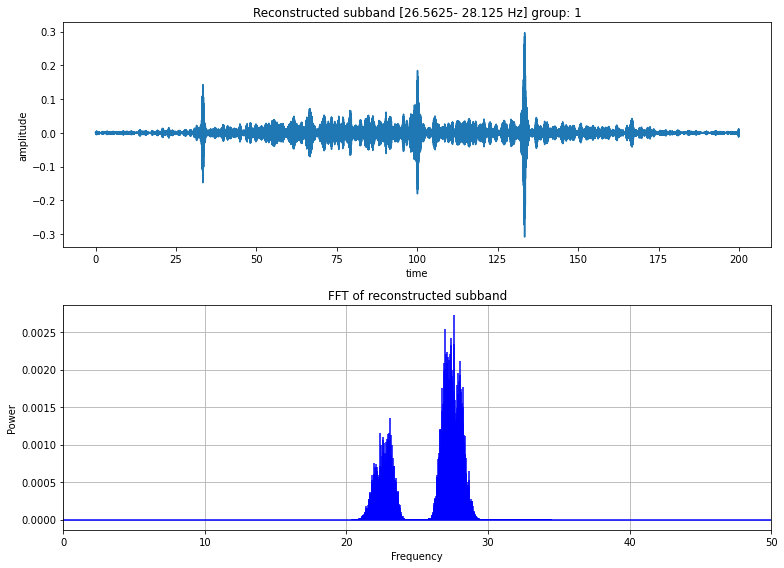

energy of recovered signal: 0.0002711079643047939
kurtosis of recovered signal: 58.26152238742518
crest factor of recovered signal: 3.9341778667627736
entropy of recovered signal: 7.437602839956752

energy of node coefficients: 0.008231842500946442
kurtosis of node coefficients: 23.319968219481986
crest factor of node coefficients: 4.206346171925105
entropy of node coefficinets: 4.467608631008722


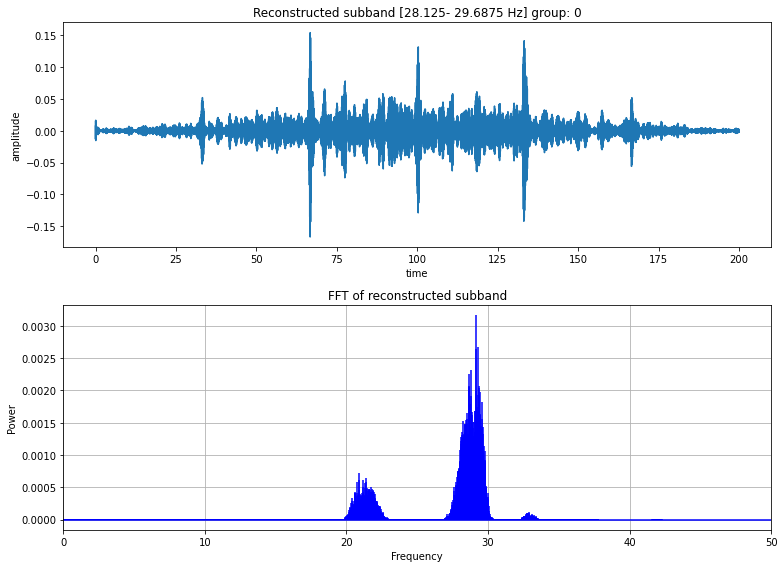

energy of recovered signal: 0.00020772982730387057
kurtosis of recovered signal: 15.15645276247107
crest factor of recovered signal: -0.23834286824764794
entropy of recovered signal: 8.139894657646446

energy of node coefficients: 0.006283141292010239
kurtosis of node coefficients: 14.838596719758316
crest factor of node coefficients: 3.6986329329892955
entropy of node coefficinets: 4.788318408126745


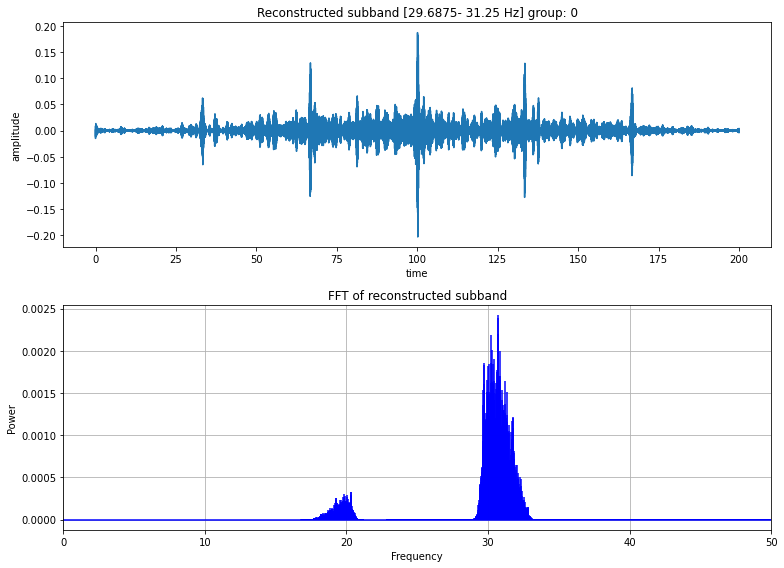

energy of recovered signal: 0.00019241133364578073
kurtosis of recovered signal: 24.217973301065115
crest factor of recovered signal: 1.8084737308271621
entropy of recovered signal: 7.975964420101156

energy of node coefficients: 0.005821640611903454
kurtosis of node coefficients: 19.115468160274542
crest factor of node coefficients: 4.787223719153995
entropy of node coefficinets: 4.720444916933767


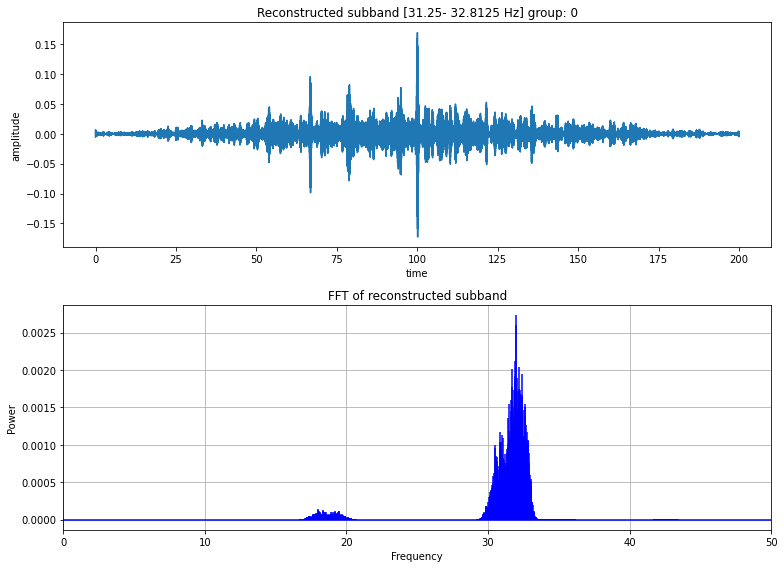

energy of recovered signal: 0.00016834764052733438
kurtosis of recovered signal: 18.50597491842186
crest factor of recovered signal: 0.9799695946861011
entropy of recovered signal: 8.189335891494876

energy of node coefficients: 0.005107870405089258
kurtosis of node coefficients: 13.276794480257397
crest factor of node coefficients: 4.391135488383121
entropy of node coefficinets: 4.970390840401172


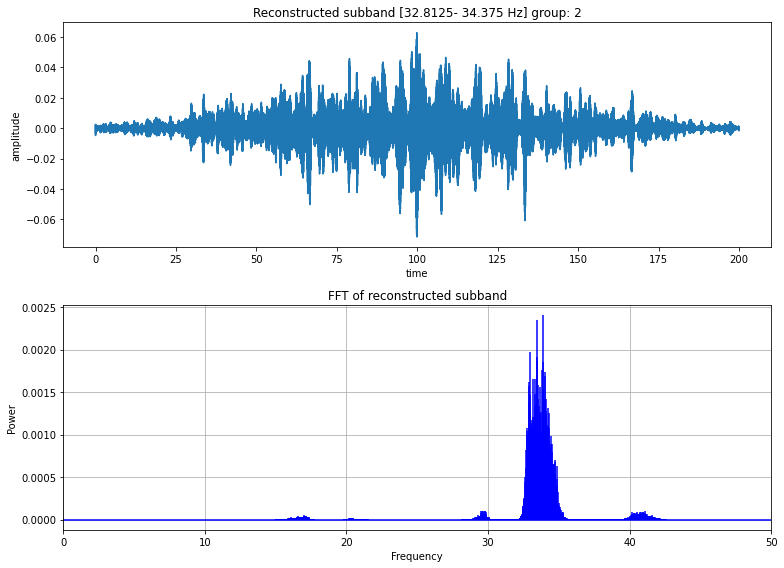

energy of recovered signal: 0.00013648806405967723
kurtosis of recovered signal: 3.313158651849303
crest factor of recovered signal: -5.762351728334693
entropy of recovered signal: 8.643209891309443

energy of node coefficients: 0.004147931621669565
kurtosis of node coefficients: 6.295884987903406
crest factor of node coefficients: -0.2705366700759479
entropy of node coefficinets: 5.224447774632693


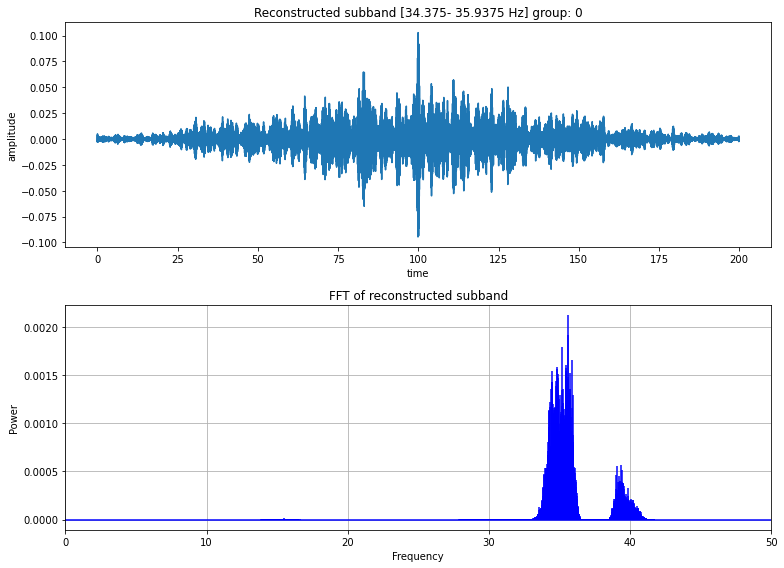

energy of recovered signal: 0.00012714202803213202
kurtosis of recovered signal: 6.156168124587822
crest factor of recovered signal: -2.3025083605000076
entropy of recovered signal: 8.50728501786544

energy of node coefficients: 0.003848923894011705
kurtosis of node coefficients: 6.934514764202432
crest factor of node coefficients: 1.5561813440777328
entropy of node coefficinets: 5.191488319736136


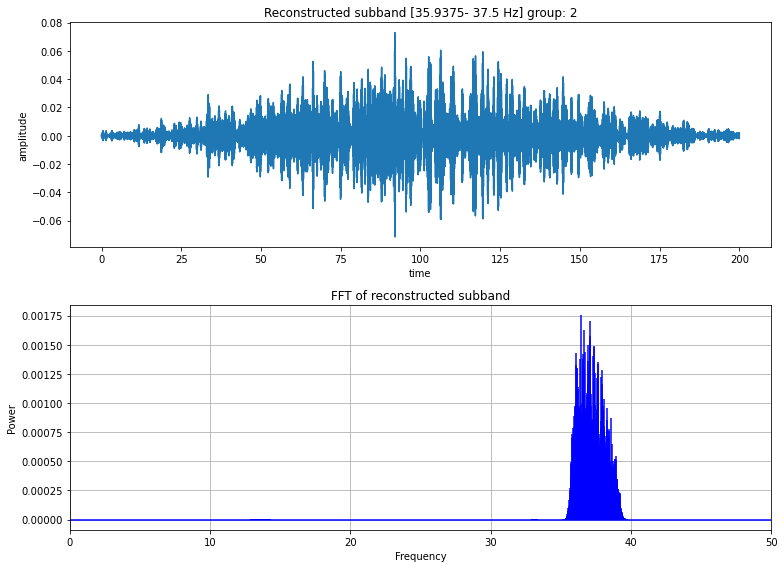

energy of recovered signal: 0.00012496365755116555
kurtosis of recovered signal: 3.8671198877270525
crest factor of recovered signal: -5.211374613730355
entropy of recovered signal: 8.557666290344642

energy of node coefficients: 0.003769431703445206
kurtosis of node coefficients: 4.807491336082036
crest factor of node coefficients: -3.1318924269357145
entropy of node coefficinets: 5.33224395062219


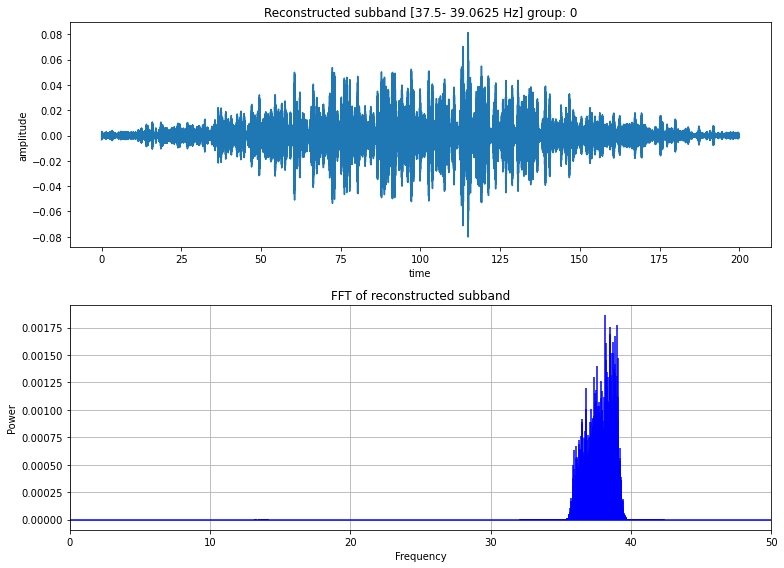

energy of recovered signal: 0.00012203275305910353
kurtosis of recovered signal: 4.7161394328896
crest factor of recovered signal: -4.156568492171492
entropy of recovered signal: 8.474833375372008

energy of node coefficients: 0.0036836264978001446
kurtosis of node coefficients: 5.800301487278572
crest factor of node coefficients: -0.30849656724510127
entropy of node coefficinets: 5.255803475583682


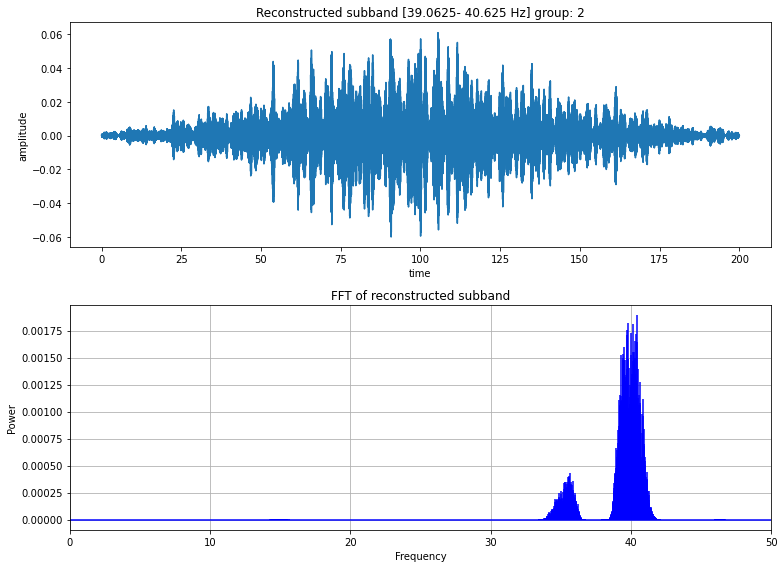

energy of recovered signal: 0.00013404578551901968
kurtosis of recovered signal: 2.862167105918747
crest factor of recovered signal: -7.091612189232894
entropy of recovered signal: 8.6515880096561

energy of node coefficients: 0.0040281162877462305
kurtosis of node coefficients: 5.401038812452195
crest factor of node coefficients: -1.447914410828757
entropy of node coefficinets: 5.245556862735117


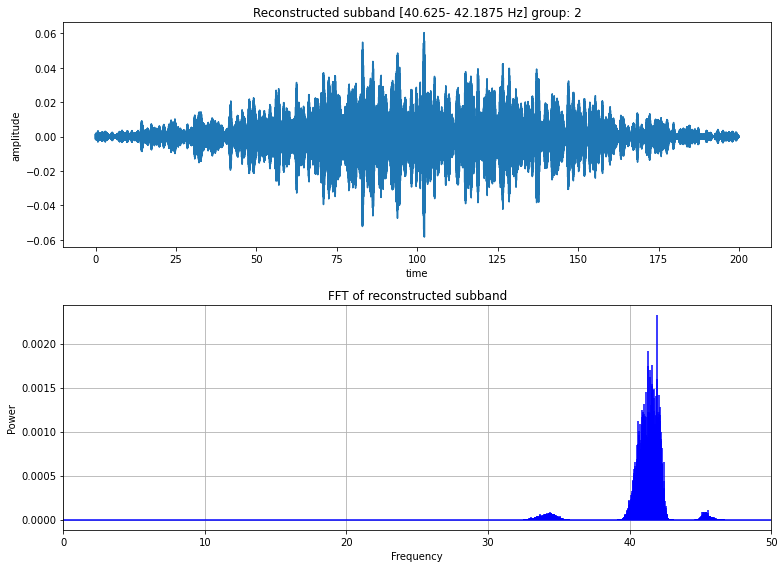

energy of recovered signal: 0.00011509707848619812
kurtosis of recovered signal: 2.1607487737565574
crest factor of recovered signal: -6.494349940180424
entropy of recovered signal: 8.765278604696643

energy of node coefficients: 0.0034607607903020623
kurtosis of node coefficients: 5.404572819520802
crest factor of node coefficients: -0.7653196377072105
entropy of node coefficinets: 5.3049045336547955


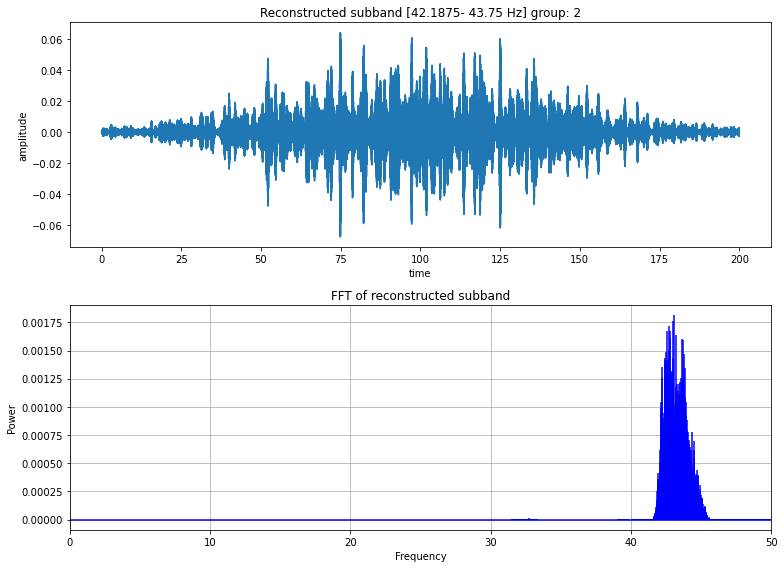

energy of recovered signal: 0.00012229074938697456
kurtosis of recovered signal: 3.989688214593386
crest factor of recovered signal: -5.796737263265774
entropy of recovered signal: 8.559785340753441

energy of node coefficients: 0.0036979930785502944
kurtosis of node coefficients: 5.722200863206475
crest factor of node coefficients: -0.8119827181664409
entropy of node coefficinets: 5.240070929392985


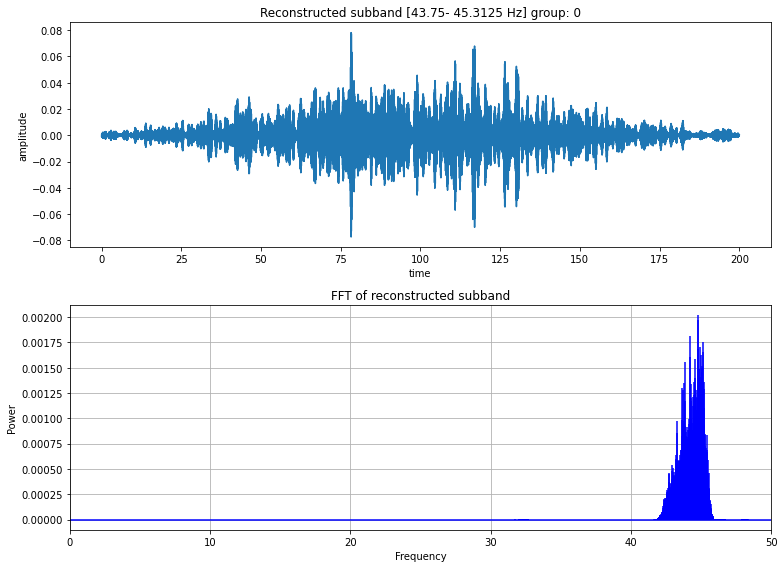

energy of recovered signal: 0.00012129502097235104
kurtosis of recovered signal: 4.299221761614067
crest factor of recovered signal: -4.4864719781188995
entropy of recovered signal: 8.590333657284733

energy of node coefficients: 0.0036644277490991027
kurtosis of node coefficients: 7.218087297429603
crest factor of node coefficients: 1.1585826245335487
entropy of node coefficinets: 5.206274746934953


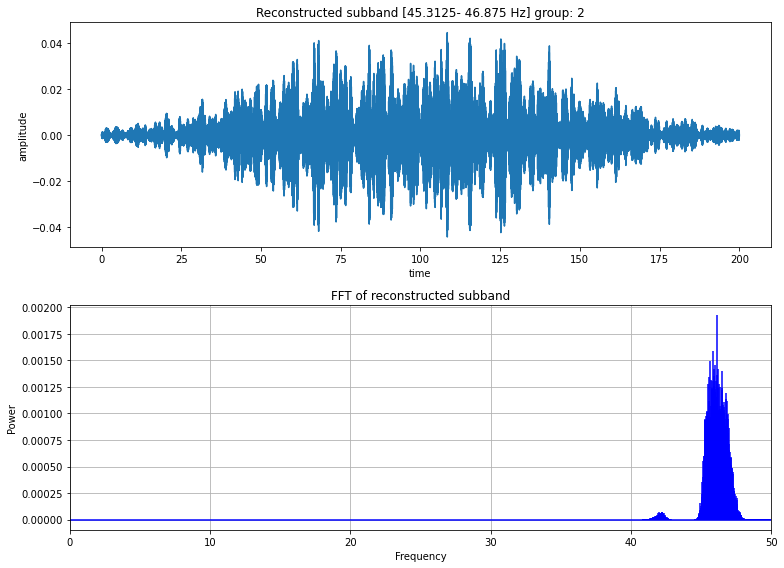

energy of recovered signal: 0.00010250835384599794
kurtosis of recovered signal: 1.7987875097416266
crest factor of recovered signal: -8.629773821546188
entropy of recovered signal: 8.78327531054261

energy of node coefficients: 0.0030856468406976053
kurtosis of node coefficients: 4.527157551045653
crest factor of node coefficients: -2.206620229017033
entropy of node coefficinets: 5.398330206888838


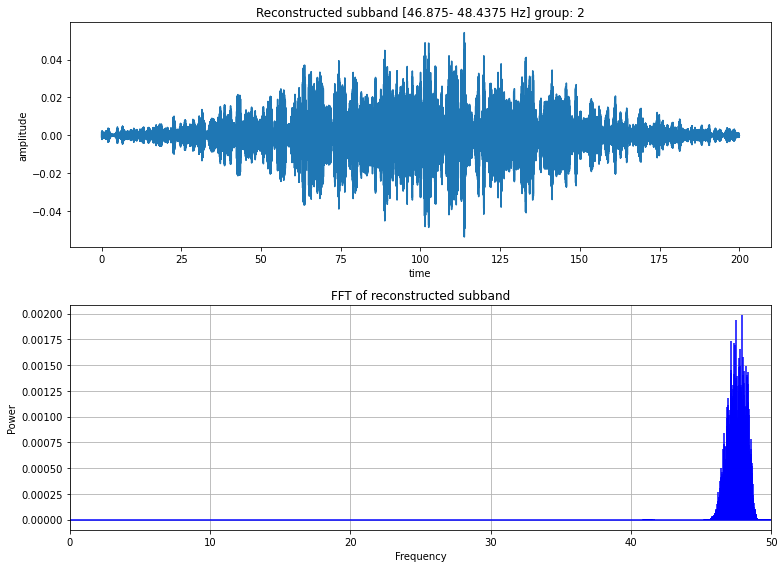

energy of recovered signal: 0.00012012895032201627
kurtosis of recovered signal: 1.8730759750530233
crest factor of recovered signal: -7.6108651482678935
entropy of recovered signal: 8.77541832584708

energy of node coefficients: 0.00362183576474018
kurtosis of node coefficients: 4.9278859591263355
crest factor of node coefficients: -1.568227018994349
entropy of node coefficinets: 5.307666364069971


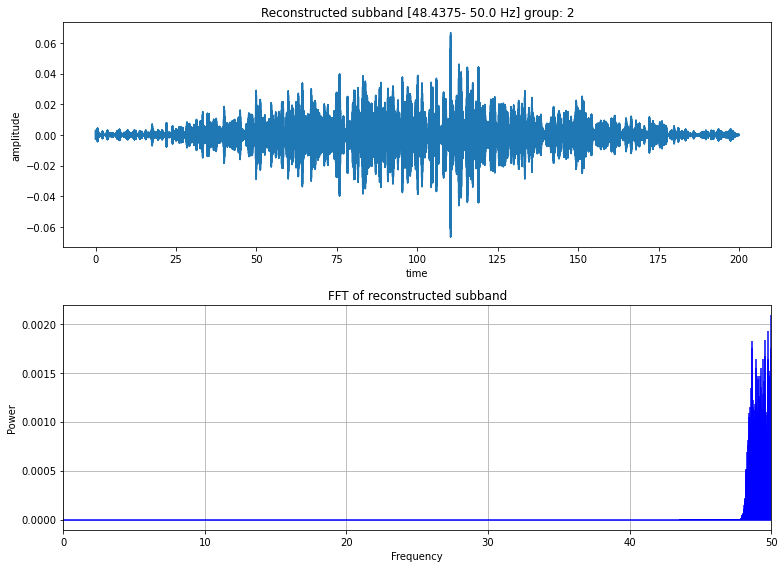

energy of recovered signal: 0.00011863499534549095
kurtosis of recovered signal: 3.000846001148421
crest factor of recovered signal: -5.752532459907566
entropy of recovered signal: 8.69046896344568

energy of node coefficients: 0.003568048625167459
kurtosis of node coefficients: 5.362182148470707
crest factor of node coefficients: -0.5445645521801676
entropy of node coefficinets: 5.308488679472426


array([-0.00886426,  0.01280575,  0.12689578, ..., -0.05061431,
       -0.03665059,  0.00108174])

In [33]:
plot_reconstructions(rec, group=labels)

# Appendix

### kurtosis and crest factor calculations
testing kurtosis and crest factor calculations on wavelet packet coefficients and reconstructed waves

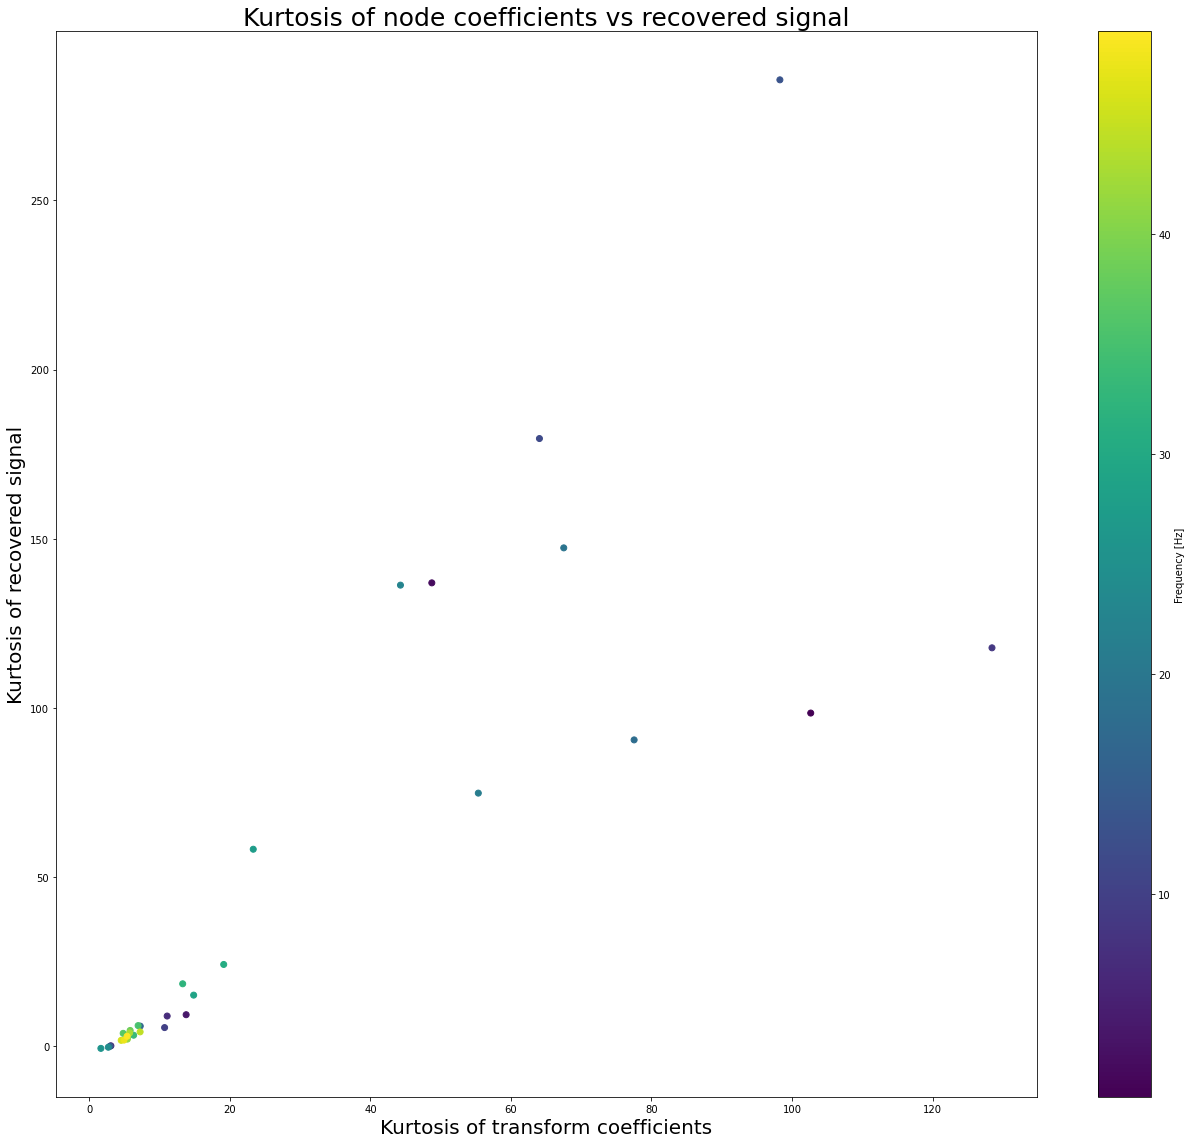

In [41]:
# Calculate frequenciens for plotting
cent_freqs = [
    round(1 / 2 * sum(node.frequency_range), 1)
    for node in tr_ob.get_level(order="freq")
]
cent_freqs = np.array(cent_freqs)
sparse_cent_freqs = [
    cent_freq if id % 1 == 0 else "" for id, cent_freq in enumerate(cent_freqs)
]

# Gather data
coef_kurtosis = [node.kurtosis for node, *_ in rec]
kurtosis = [sc.kurtosis(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_kurtosis, kurtosis, c=cent_freqs)
ax.set_title("Kurtosis of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Kurtosis of transform coefficients", fontsize=20)
ax.set_ylabel("Kurtosis of recovered signal", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()

(<wavelet_transform.wpt.transform_node.Node object at 0x0000021D84D59DF0>, array([ 0.02664881,  0.02686381,  0.02693537, ..., -0.0171618 ,
       -0.01865206, -0.02018222]), array([ 7.91894584e-03+0.00000000e+00j, -3.37913287e-03-1.07183569e-04j,
       -7.61805537e-04+8.78787360e-05j, ...,
        2.37311856e-06-1.14098799e-09j,  2.37311857e-06-7.60658627e-10j,
        2.37311857e-06-3.80329304e-10j]), 0.0022555317877427507, 98.49941417362042, 1.7935034566800343, 5.913895286311434)


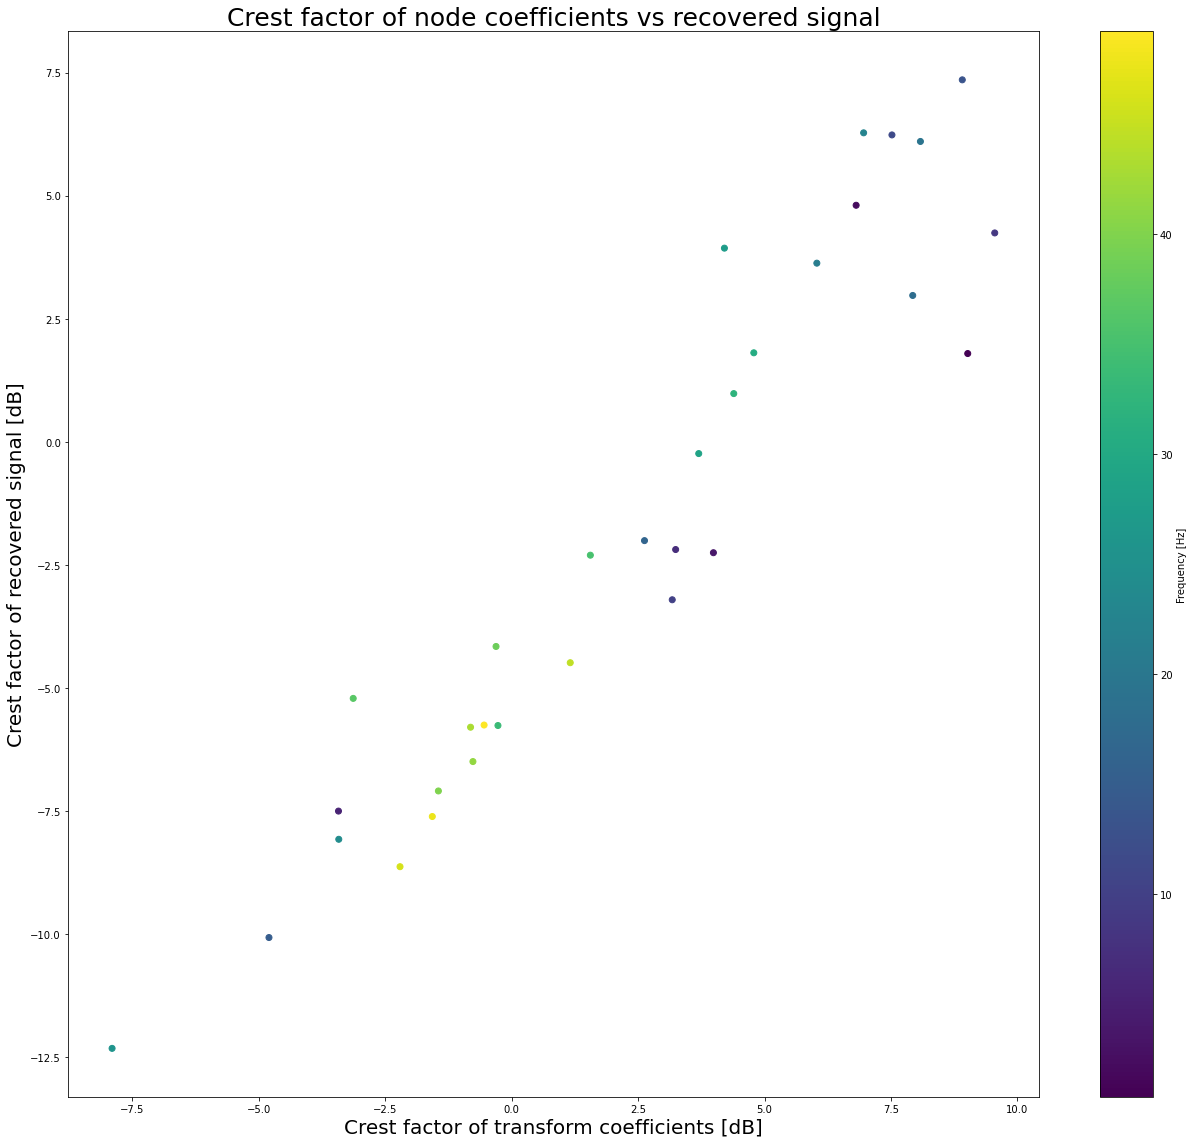

In [40]:
# gather data
coef_crest = [node.crest_factor for node, *_ in rec]
crest = [stats.crest_factor(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_crest, crest, c=cent_freqs)
ax.set_title("Crest factor of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Crest factor of transform coefficients [dB]", fontsize=20)
ax.set_ylabel("Crest factor of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()

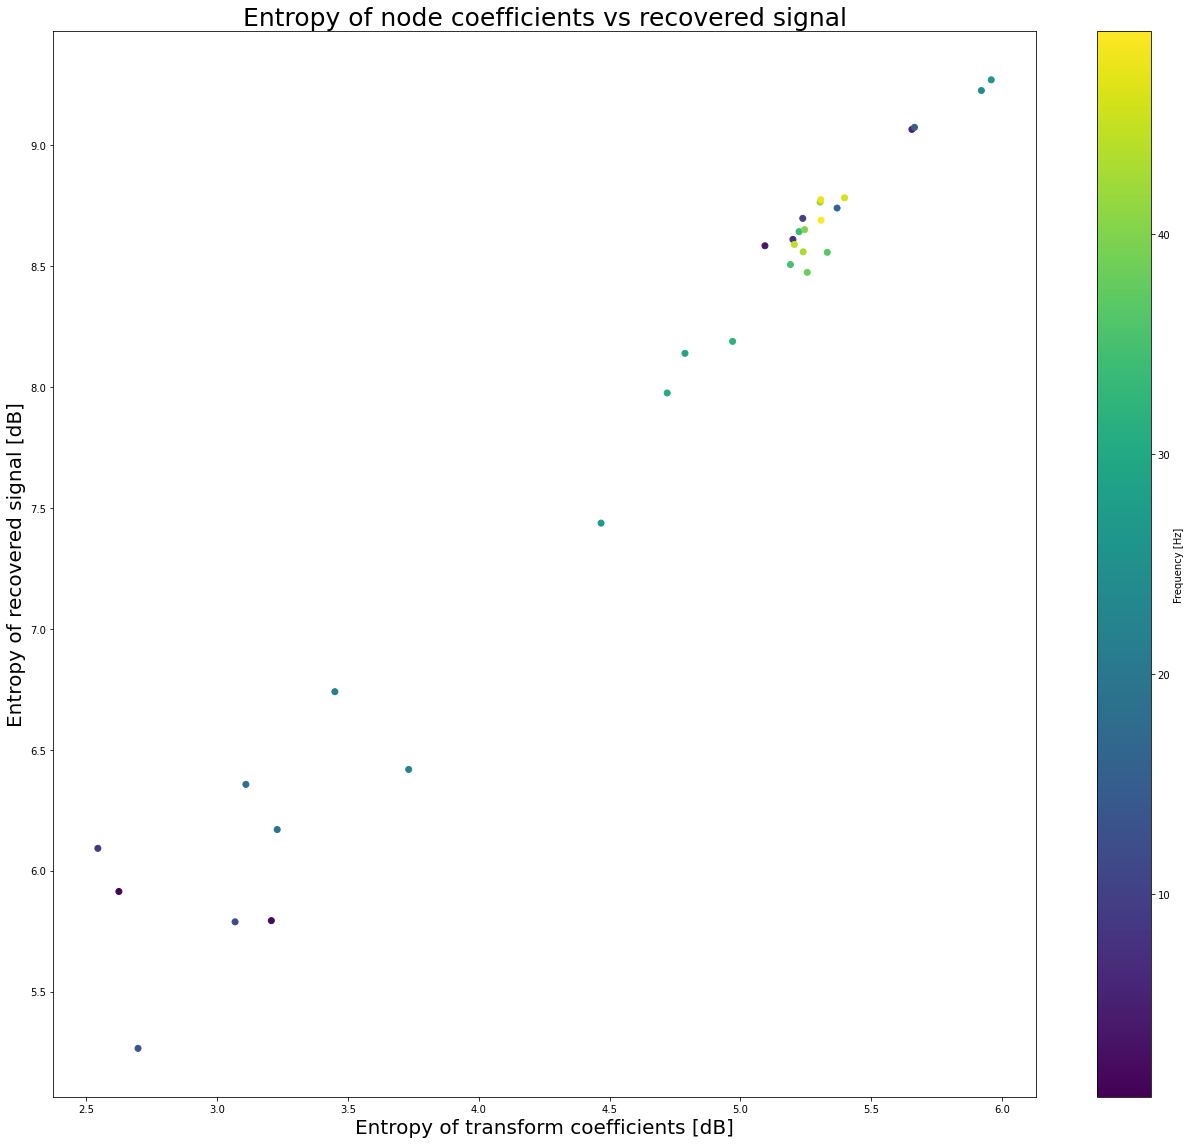

In [43]:
# gather data
coef_entropy = [node.entropy for node, *_ in rec]
entropy = [stats.entropy(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_entropy, entropy, c=cent_freqs)
ax.set_title("Entropy of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Entropy of transform coefficients [dB]", fontsize=20)
ax.set_ylabel("Entropy of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()